In [ ]:
# 1-Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#2-Load the data
train_data = pd.read_csv("../data/train.csv")
test_data = pd.read_csv("../data/test.csv")

In [5]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [8]:
# 3-check the data set dimensions
print("Training data dimensions:", train_data.shape)
print("Test data dimensions:", test_data.shape)

Training data dimensions: (891, 12)
Test data dimensions: (418, 11)


In [9]:
#4- display the data types of each column
print("Training columns:")
print(train_data.columns)

print("\nTesting columns:")
print(test_data.columns)

Training columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

Testing columns:
Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


In [10]:
#5-basic info 
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [11]:
#6- check for missing values
train_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [12]:
#7-check the distribution of the target variable (Survived)
train_data["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

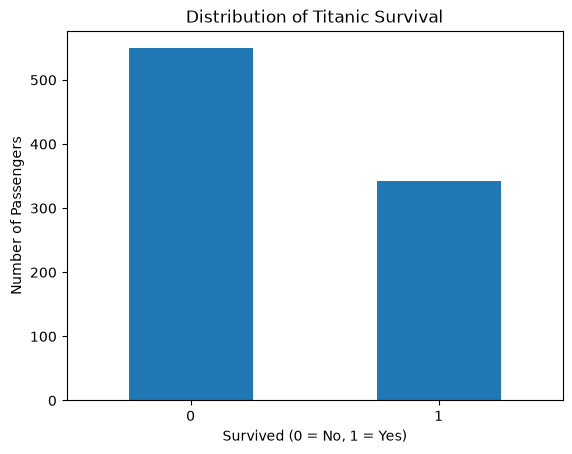

In [14]:

# Step-8: Visualize the distribution of the target variable

import matplotlib.pyplot as plt

# Count passengers in each survival class
survival_counts = train_data["Survived"].value_counts().sort_index()

# Create a bar chart
survival_counts.plot(kind="bar")

# Add chart labels and title
plt.title("Distribution of Titanic Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

# Display the chart
plt.show()


In [15]:

# Step 9: Check for missing values in the training dataset

train_data.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:

# Step 10: Check the data types of each column

train_data.dtypes


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [17]:

# Step 11: Display descriptive statistics for numerical columns
train_data.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:

# Step 12: Compare survival counts by gender

train_data.groupby("Sex")["Survived"].value_counts()


Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

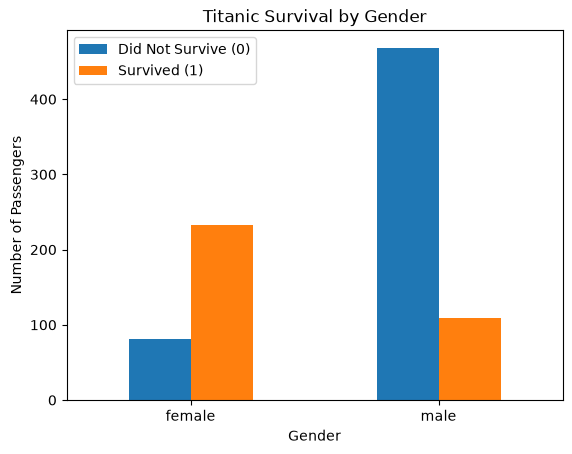

In [19]:

# Step 13: Visualize survival counts by gender

# Group passengers by gender and survival outcome
gender_survival = train_data.groupby(["Sex", "Survived"]).size().unstack()

# Create a bar chart
gender_survival.plot(kind="bar")

# Add the chart title and labels
plt.title("Titanic Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

# Display the legend and chart
plt.legend(["Did Not Survive (0)", "Survived (1)"])
plt.show()


In [20]:

# Step 14: Count survival outcomes for each passenger class

train_data.groupby("Pclass")["Survived"].value_counts().sort_index()


Pclass  Survived
1       0            80
        1           136
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64

In [21]:

# step 15: Calculate the survival rate for each passenger class
train_data.groupby("Pclass")["Survived"].mean() * 100


Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

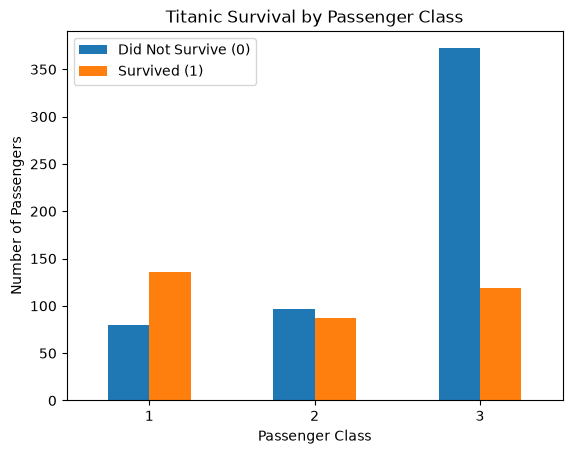

In [ ]:

# Step 16: Visualize survival by passenger class

# Group passengers by class and survival outcome
class_survival = train_data.groupby(["Pclass", "Survived"]).size().unstack()

# Create a bar chart
class_survival.plot(kind="bar")

# Add the chart title and labels
plt.title("Titanic Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)

# Add a legend
plt.legend(["Did Not Survive (0)", "Survived (1)"])

# Display the chart
plt.show()


In [ ]:

# Step 17: Display basic statistics about passenger ages

train_data["Age"].describe()


count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [24]:

# Step 18: Compare the average age of survivors and non-survivors

train_data.groupby("Survived")["Age"].mean()


Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

In [26]:

# Step 19: Count survival outcomes by embarkation port

train_data.groupby("Embarked")["Survived"].value_counts()


Embarked  Survived
C         1            93
          0            75
Q         0            47
          1            30
S         0           427
          1           217
Name: count, dtype: int64

In [27]:

# Step 20: Calculate survival rates by embarkation port

train_data.groupby("Embarked")["Survived"].mean() * 100


Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64

In [28]:

# Step 21: Calculate family size for each passenger

train_data["FamilySize"] = train_data["SibSp"] + train_data["Parch"] + 1

# Display the first five family sizes
train_data[["SibSp", "Parch", "FamilySize"]].head()


,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [29]:

# Step 22: Compare survival rates by family size

train_data.groupby("FamilySize")["Survived"].mean() * 100


FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

In [30]:

# Step 23: Check the shapes of the training and test datasets

print("Training dataset shape:", train_data.shape)
print("Test dataset shape:", test_data.shape)


Training dataset shape: (891, 13)
Test dataset shape: (418, 11)


In [31]:

# Step 24: Inspect the training and test datasets

# Check the number of rows and columns
print("Training dataset shape:", train_data.shape)
print("Test dataset shape:", test_data.shape)

# Display the column names
print("\nTraining dataset columns:")
print(train_data.columns.tolist())

print("\nTest dataset columns:")
print(test_data.columns.tolist())


Training dataset shape: (891, 13)
Test dataset shape: (418, 11)

Training dataset columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize']

Test dataset columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [32]:
# Step 25:  Calculate the total number of family members traveling with each passenger,
# including the passenger themselves
test_data["FamilySize"] = test_data["SibSp"] + test_data["Parch"] + 1

# Display the first five rows to check the new column
test_data[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,0,0,1
1,1,0,2
2,0,0,1
3,0,0,1
4,1,1,3


In [33]:
# Step 26: Check missing values in the training and test datasets

# Count missing values in each column
print("Missing values in training dataset:")
print(train_data.isnull().sum())

print("\nMissing values in test dataset:")
print(test_data.isnull().sum())


Missing values in training dataset:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
FamilySize       0
dtype: int64

Missing values in test dataset:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
FamilySize       0
dtype: int64


In [34]:
# Step 27A: Separate the target from the features

from sklearn.model_selection import train_test_split

# The target is the value we want to predict
X = train_data.drop(columns=["Survived"])

# The target values: 0 = did not survive, 1 = survived
y = train_data["Survived"]

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the shapes
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (712, 12)
Validation features: (179, 12)
Training target: (712,)
Validation target: (179,)


In [35]:
# Step 28: Select the features for our first model

# Choose the columns we want the model to learn from
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize"
]

# Keep only these features in the training and validation sets
X_train = X_train[features]
X_val = X_val[features]

# Select the same features from the test dataset
test_features = test_data[features]

# Display the selected columns
print("Selected features:")
print(X_train.columns.tolist())

print("\nTraining features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", test_features.shape)

Selected features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize']

Training features shape: (712, 8)
Validation features shape: (179, 8)
Test features shape: (418, 8)


In [37]:
# Step 29: Handle missing values

# Find the median age from the training features
age_median = X_train["Age"].median()

# Find the most frequent Embarked value
embarked_mode = X_train["Embarked"].mode()[0]

# Find the median fare from the training features
fare_median = X_train["Fare"].median()

# Fill missing values in the training features
X_train["Age"] = X_train["Age"].fillna(age_median)
X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)

# Fill missing values in the validation features
X_val["Age"] = X_val["Age"].fillna(age_median)
X_val["Embarked"] = X_val["Embarked"].fillna(embarked_mode)

# Fill missing values in the test features
test_features["Age"] = test_features["Age"].fillna(age_median)
test_features["Fare"] = test_features["Fare"].fillna(fare_median)
test_features["Embarked"] = test_features["Embarked"].fillna(embarked_mode)

# Check for remaining missing values
print("Missing values in training features:")
print(X_train.isnull().sum())

print("\nMissing values in validation features:")
print(X_val.isnull())

Missing values in training features:
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
dtype: int64

Missing values in validation features:
     Pclass    Sex    Age  SibSp  Parch   Fare  Embarked  FamilySize
565   False  False  False  False  False  False     False       False
160   False  False  False  False  False  False     False       False
553   False  False  False  False  False  False     False       False
860   False  False  False  False  False  False     False       False
241   False  False  False  False  False  False     False       False
..      ...    ...    ...    ...    ...    ...       ...         ...
880   False  False  False  False  False  False     False       False
91    False  False  False  False  False  False     False       False
883   False  False  False  False  False  False     False       False
473   False  False  False  False  False  False     False       False
637   False  False  Fal

In [38]:
# Step 29: Verify that no missing values remain

print("Training missing values:")
print(X_train.isnull().sum())

print("\nValidation missing values:")
print(X_val.isnull().sum())

print("\nTest missing values:")
print(test_features.isnull().sum())

Training missing values:
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
dtype: int64

Validation missing values:
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
dtype: int64

Test missing values:
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
dtype: int64


In [39]:
# Step 30: Convert categorical features into numbers

# Convert text columns into numerical columns
X_train = pd.get_dummies(X_train, columns=["Sex", "Embarked"], dtype=int)
X_val = pd.get_dummies(X_val, columns=["Sex", "Embarked"], dtype=int)
test_features = pd.get_dummies(test_features, columns=["Sex", "Embarked"], dtype=int)

# Make sure all datasets have the same columns
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
test_features = test_features.reindex(columns=X_train.columns, fill_value=0)

# Display the resulting columns
print("Training columns:")
print(X_train.columns.tolist())

print("\nTraining features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", test_features.shape)

# Display the first five rows
X_train.head()

Training columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Training features shape: (712, 11)
Validation features shape: (179, 11)
Test features shape: (418, 11)


,Pclass,Age,SibSp,Parch,Fare,FamilySize,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,3,28.5,0,0,56.4958,1,0,1,0,0,1
481,2,28.5,0,0,0.0000,1,0,1,0,0,1
527,1,28.5,0,0,221.7792,1,0,1,0,0,1
855,3,18.0,0,1,9.3500,2,1,0,0,0,1
801,2,31.0,1,1,26.2500,3,1,0,0,0,1


In [40]:
# Step 31: Check the prepared datasets before training

# Check the data types
print("Training data types:")
print(X_train.dtypes)

# Check for missing values
print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in validation data:", X_val.isnull().sum().sum())
print("Missing values in test data:", test_features.isnull().sum().sum())

# Check that the feature columns match
print("\nTraining and validation columns match:", 
      list(X_train.columns) == list(X_val.columns))

print("Training and test columns match:", 
      list(X_train.columns) == list(test_features.columns))

Training data types:
Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
FamilySize      int64
Sex_female      int64
Sex_male        int64
Embarked_C      int64
Embarked_Q      int64
Embarked_S      int64
dtype: object

Missing values in training data: 0
Missing values in validation data: 0
Missing values in test data: 0

Training and validation columns match: True
Training and test columns match: True


In [41]:
# Step 32: Train a Logistic Regression model

# Import the Logistic Regression algorithm
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model using the training features and their correct answers
model.fit(X_train, y_train)

# Confirm that training is complete
print("Model training completed successfully!")

Model training completed successfully!


In [42]:
# Step 33: Predict survival for validation passengers

# Use the trained model to make predictions
y_preds = model.predict(X_val)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_preds[:10])

# Display the actual survival outcomes for comparison
print("\nActual survival outcomes:")
print(y_val.iloc[:10].values)

First 10 predictions:
[0 0 0 0 1 0 1 0 0 0]

Actual survival outcomes:
[0 0 1 0 1 1 1 0 0 0]


In [43]:
# Step 34: Calculate the accuracy of the model

# Import the accuracy metric
from sklearn.metrics import accuracy_score

# Compare predictions with actual outcomes
accuracy = accuracy_score(y_val, y_preds)

# Display the accuracy as a percentage
print("Model accuracy:", round(accuracy * 100, 2), "%")


Model accuracy: 80.45 %


In [44]:
# Step 35: Calculate precision, recall, and F1-score

# Import the evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate precision
precision = precision_score(y_val, y_preds)

# Calculate recall
recall = recall_score(y_val, y_preds)

# Calculate F1-score
f1 = f1_score(y_val, y_preds)

# Display the results as percentages
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-score:", round(f1 * 100, 2), "%")

Precision: 79.31 %
Recall: 66.67 %
F1-score: 72.44 %


Confusion Matrix:
[[98 12]
 [23 46]]


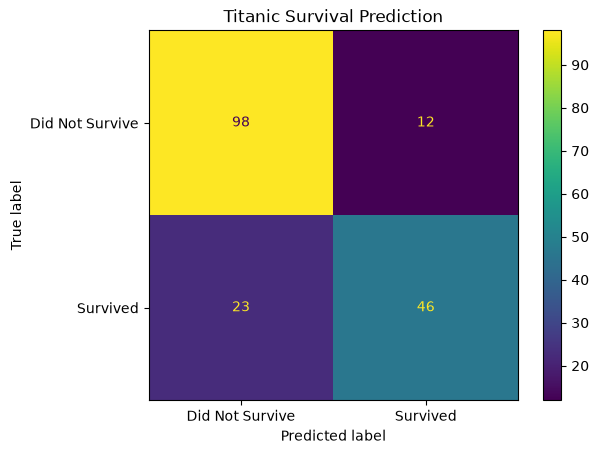

In [45]:
# Step 36A: Create a confusion matrix

# Import the confusion matrix function
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare actual outcomes with predictions
cm = confusion_matrix(y_val, y_preds)

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize the results
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("Titanic Survival Prediction")
plt.show()

In [46]:
# Step 37: Train a Random Forest model

from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [47]:
# Step 38: Make predictions using Random Forest

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict survival outcomes for the validation data
rf_preds = rf_model.predict(X_val)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_val, rf_preds)
rf_precision = precision_score(y_val, rf_preds)
rf_recall = recall_score(y_val, rf_preds)
rf_f1 = f1_score(y_val, rf_preds)

# Display the results
print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall:", round(rf_recall * 100, 2), "%")
print("F1-score:", round(rf_f1 * 100, 2), "%")

Random Forest Results
---------------------
Accuracy: 81.01 %
Precision: 77.78 %
Recall: 71.01 %
F1-score: 74.24 %


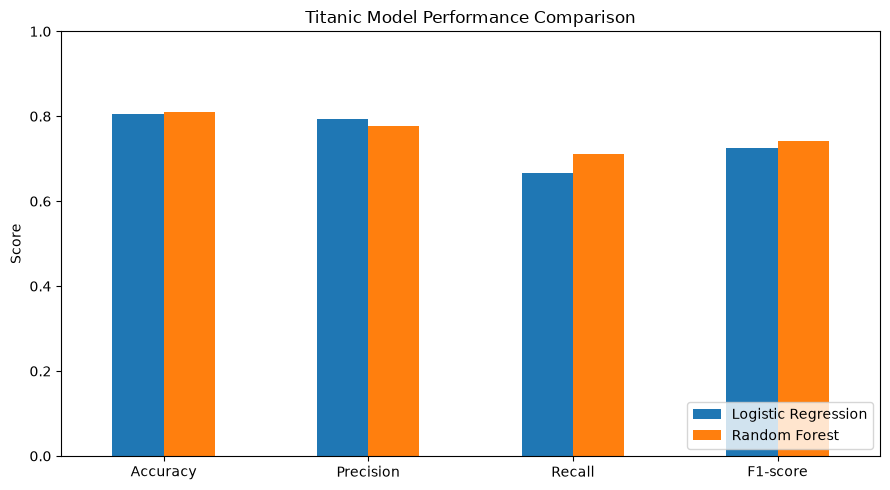

In [48]:
# Step 40: Compare model performance

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Logistic Regression": [
        accuracy, precision, recall, f1
    ],
    "Random Forest": [
        rf_accuracy, rf_precision, rf_recall, rf_f1
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])

comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Titanic Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [49]:
# Step 41: Predict survival for the test dataset

# Use the trained Random Forest model to make predictions
test_predictions = rf_model.predict(test_features)

# Display the first 10 predictions
print("First 10 test predictions:")
print(test_predictions[:10])

# Check the total number of predictions
print("Total predictions:", len(test_predictions))

First 10 test predictions:
[0 0 0 1 0 0 0 0 1 0]
Total predictions: 418


In [50]:
# Step 42: Create the submission file

# Create a DataFrame with passenger IDs and predictions
submission = pd.DataFrame({
    "PassengerId": test_data["PassengerId"],
    "Survived": test_predictions
})

# Save the DataFrame as a CSV file
submission.to_csv("../submission.csv", index=False)

# Display the first 10 rows
print(submission.head(10))

print("\nSubmission file created successfully!")

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         1
4          896         0
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0

Submission file created successfully!


In [ ]:
# Step 43: # Check the number of rows and columns
print("Submission shape:", submission.shape)

# Check column names
print("Columns:", submission.columns.tolist())

# Check for missing values
print("Missing values:")
print(submission.isnull().sum())

# Check prediction values
print("Unique predictions:", submission["Survived"].unique())

# Check passenger IDs
print("Unique passenger IDs:", submission["PassengerId"].nunique())

Submission shape: (418, 2)
Columns: ['PassengerId', 'Survived']
Missing values:
PassengerId    0
Survived       0
dtype: int64
Unique predictions: [0 1]
Unique passenger IDs: 418
